# Section 2: Data Exploration

**Student:**  
**GitHub username:**  
**Date:**  

## Goal

Produce one reproducible exploratory data analysis of a high-dimensional polymer dataset and use evidence from the analysis to answer the section's critical-thinking questions.

This is one integrated assignment, not three separate daily tasks. Organize the work in whatever order helps you build a coherent analysis.

## How to Use This Notebook

1. Copy this template to `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`.
2. Add your code only to the blank code cells.
3. Add explanations and answers to the blank Markdown cells.
4. You may add more cells when useful, but keep the section headings and required evidence.
5. Keep the raw CSV unchanged. Perform and explain any cleaning in this notebook.
6. Before submission, restart the kernel and run every cell from top to bottom.

Aim for a focused notebook that can be rerun and discussed, not a gallery of every possible chart. Clear labels, units, short interpretations, and well-chosen evidence matter more than decoration.

## Python Setup and Suggested Packages

From the repository root, install the course tools into your `uv` environment:

```bash
uv pip install pandas numpy matplotlib seaborn scikit-learn ipykernel
```

Select the project's `.venv` Python kernel in VS Code or Jupyter. These are the suggested imports:

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
```

What each package is for:

| Package | Use in this notebook |
|---|---|
| `pandas` | Load the CSV, select columns, audit values, calculate statistics and correlations, and build labeled result tables |
| `numpy` | Check numerical results, calculate cumulative variance, and work with arrays returned by scikit-learn |
| `matplotlib` | Create figures and control titles, axes, labels, and layout |
| `seaborn` | Create readable statistical plots such as histograms, box plots, heatmaps, and scatter plots |
| `scikit-learn` | Standardize the properties with `StandardScaler` and calculate PCA with `PCA` |

You may use equivalent tools, but you must explain the substitution and produce the same required evidence.

## Quick Function Reference

Use this table as a map, not as a list of functions that must all appear in your notebook.

| Task | Suggested functions or attributes | What to check |
|---|---|---|
| Load data | `pd.read_csv()` | The path is relative and the result is a DataFrame |
| Preview structure | `.head()`, `.shape`, `.columns`, `.info()`, `.dtypes` | Rows and columns mean what you think they mean |
| Missingness and duplicates | `.isna().sum()`, `.duplicated().sum()`, `.nunique()` | Non-null values can still be suspicious |
| Select analytical variables | `.select_dtypes(include="number")`, `.drop(columns=...)` | Explicitly remove `id`; save the 13 property names |
| Descriptive statistics | `.describe()`, `.mean()`, `.median()`, `.var()`, `.std()`, `.quantile()` | Label statistics and preserve units |
| Inspect selected rows | `.loc[]`, `.sort_values()`, Boolean filters | Look at the original records behind unusual points |
| Distribution plots | `sns.histplot()`, optional `kde=True` | Bins and smoothing choices affect appearance |
| Box plots | `sns.boxplot()` | Whisker points are flags for investigation, not automatic errors |
| Correlations | `.corr(method="pearson")`, `.corr(method="spearman")` | Correlation measures association, not causation |
| Correlation heatmaps | `sns.heatmap()` | Keep labels readable and use a scale centered at zero |
| Relationship plots | `sns.scatterplot()` or `plt.scatter()` | Look for curves, groups, ties, and influential values |
| Standardization | `StandardScaler()`, `.fit_transform()`, `.mean_`, `.scale_` | PCA input should have approximately zero column means and unit population variance |
| PCA | `PCA()`, `.fit_transform()`, `.explained_variance_ratio_`, `.components_` | Know the shape and meaning of every returned array |
| Cumulative variance | `np.cumsum()` | Decide how many components meet your stated purpose |
| PCA plots | `plt.plot()`, `plt.bar()`, `plt.scatter()` | Label component numbers and variance percentages |
| Labeled tables | `pd.DataFrame()` | Attach property names to component weights |

Useful habit: after every major transformation, print or display its type and shape before plotting it.

## Dataset

Analyze `sections/s02/homework/openpoly_calculated_properties.csv` and read `sections/s02/homework/DATASET.md` before beginning.

The CSV contains 1,000 calculated polymers, identity and structure fields, metadata, and 13 numeric quantum-chemical properties. Use those 13 properties for the main multivariate analysis. Exclude `id`: it is an identifier, not a measured or calculated polymer property.

Load the CSV using a repository-relative path. The notebook must not depend on an absolute path from your computer.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
data = pd.read_csv("../../homework/openpoly_calculated_properties.csv")

Issue: code '''data = pd.read_csv("sections/s02/homework/openpoly_calculated_properties.csv")''' didn't work due to where the computer started searching - resulted in file not found

Fix: code '''data = pd.read_csv("../../homework/openpoly_calculated_properties.csv")''' allows the computer the search the folders above

In [4]:
print(data.head())

   id                Name                             reactant_1  \
0   1  OMG_polymer_189323   O=C(O)Cc1c2ccccc2c(CC(=O)O)c2ccccc12   
1   2  OMG_polymer_169676  O=C(O)c1ccccc1C(=O)NC(C(=O)O)c1ccccc1   
2   3  OMG_polymer_105232              O=C(O)CC(CC(=O)O)c1ccncc1   
3   4  OMG_polymer_199732         COc1ccccc1C=NN(CC(=O)O)CC(=O)O   
4   5  OMG_polymer_175493      O=C(O)C1CCC(C(=O)O)N(Cc2ccccc2)C1   

                          reactant_2  \
0  Nc1ccc(Nc2ccc(N)cc2S(=O)(=O)O)cc1   
1              Nc1ccc(F)c(C(=O)O)c1N   
2                       NCC(N)C(=O)O   
3             Nc1cc(Br)cc(C(=O)O)c1N   
4        Nc1cc(C(=O)O)ccc1S(N)(=O)=O   

                                             psmiles  \
0  *Nc1ccc(Nc2ccc(NC(=O)Cc3c4ccccc4c(CC(*)=O)c4cc...   
1  *Nc1ccc(F)c(C(=O)O)c1NC(=O)c1ccccc1C(=O)NC(C(*...   
2              *NCC(NC(=O)CC(CC(*)=O)c1ccncc1)C(=O)O   
3  *Nc1cc(Br)cc(C(=O)O)c1NC(=O)CN(CC(*)=O)N=Cc1cc...   
4  *Nc1cc(C(=O)O)ccc1S(=O)(=O)NC(=O)C1CCC(C(*)=O)...   

             

In [5]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   id                                              1000 non-null   int64  
 1   Name                                            1000 non-null   str    
 2   reactant_1                                      1000 non-null   str    
 3   reactant_2                                      1000 non-null   str    
 4   psmiles                                         1000 non-null   str    
 5   SMILES                                          1000 non-null   str    
 6   reaction_type                                   1000 non-null   str    
 7   Energy_Hatree                                   1000 non-null   float64
 8   es                                              1000 non-null   float64
 9   Isotropic_Polarizability_au                     1000 

In [6]:
print(data.shape)

(1000, 23)


In [7]:
print(data.columns)

Index(['id', 'Name', 'reactant_1', 'reactant_2', 'psmiles', 'SMILES',
       'reaction_type', 'Energy_Hatree', 'es', 'Isotropic_Polarizability_au',
       'HOMO_eV', 'LUMO_eV', 'Inner_energy_correction_Hatree',
       'Thermal_correction_to_Enthalpy_Hatree',
       'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree',
       'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree',
       'HOMO_LUMO_Gap_eV', 'Software', 'Theory_Level', 'Source'],
      dtype='str')


In [8]:
print(data.dtypes)

id                                                  int64
Name                                                  str
reactant_1                                            str
reactant_2                                            str
psmiles                                               str
SMILES                                                str
reaction_type                                         str
Energy_Hatree                                     float64
es                                                float64
Isotropic_Polarizability_au                       float64
HOMO_eV                                           float64
LUMO_eV                                           float64
Inner_energy_correction_Hatree                    float64
Thermal_correction_to_Enthalpy_Hatree             float64
Thermal_correction_to_Gibbs_Free_Energy_Hatree    float64
Entropy_Hatree                                    float64
Dipole_Debye                                      float64
Gibbs_Free_Ene

In [9]:
data.isnull().sum()

id                                                0
Name                                              0
reactant_1                                        0
reactant_2                                        0
psmiles                                           0
SMILES                                            0
reaction_type                                     0
Energy_Hatree                                     0
es                                                0
Isotropic_Polarizability_au                       0
HOMO_eV                                           0
LUMO_eV                                           0
Inner_energy_correction_Hatree                    0
Thermal_correction_to_Enthalpy_Hatree             0
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0
Entropy_Hatree                                    0
Dipole_Debye                                      0
Gibbs_Free_Energy_Hatree                          0
Enthalpy_Hatree                                   0
HOMO_LUMO_Ga

In [10]:
data.nunique()

id                                                1000
Name                                              1000
reactant_1                                         686
reactant_2                                         156
psmiles                                           1000
SMILES                                            1000
reaction_type                                        1
Energy_Hatree                                      927
es                                                 881
Isotropic_Polarizability_au                        927
HOMO_eV                                            882
LUMO_eV                                            887
Inner_energy_correction_Hatree                     965
Thermal_correction_to_Enthalpy_Hatree                2
Thermal_correction_to_Gibbs_Free_Energy_Hatree     965
Entropy_Hatree                                     964
Dipole_Debye                                       965
Gibbs_Free_Energy_Hatree                           965
Enthalpy_H

## 1. Audit the Dataset

Use the blank cells below to:

- report the dataset's shape, column names, data types, missing-value counts, exact duplicates, and number of unique values per column;
- create a compact data dictionary that classifies columns as identifiers, chemical structures, categorical metadata, or numeric analytical variables;
- inspect zeros, extreme values, and constant columns; and
- identify at least two values or patterns that need investigation, even if pandas reports no missing values.

Do not decide that a value is valid merely because it is non-null. Do not delete an observation without documenting the evidence and reasoning.

In [11]:
data.duplicated().sum()

np.int64(0)

In [12]:
no_id_data = data.drop(columns="id")
dictionary = pd.DataFrame({
    "Column Name": no_id_data.columns, 
    "Classification": [
        "Identifier",
        "Chemical structure",
        "Chemical structure",
        "Chemical structure",
        "Chemical structure",
        "Categorical metadata",
        *["Numeric analytical variable"] * 13,
        "Categorical metadata",
        "Categorical metadata",
        "Categorical metadata"
    ]
})
dictionary 

,Column Name,Classification
0,Name,Identifier
1,reactant_1,Chemical structure
2,reactant_2,Chemical structure
3,psmiles,Chemical structure
4,SMILES,Chemical structure
5,reaction_type,Categorical metadata
6,Energy_Hatree,Numeric analytical variable
7,es,Numeric analytical variable
8,Isotropic_Polarizability_au,Numeric analytical variable
9,HOMO_eV,Numeric analytical variable


In [13]:
(no_id_data.select_dtypes(include="number") == 0).sum()

Energy_Hatree                                     74
es                                                 0
Isotropic_Polarizability_au                       74
HOMO_eV                                           74
LUMO_eV                                           74
Inner_energy_correction_Hatree                    36
Thermal_correction_to_Enthalpy_Hatree             36
Thermal_correction_to_Gibbs_Free_Energy_Hatree    36
Entropy_Hatree                                    36
Dipole_Debye                                      36
Gibbs_Free_Energy_Hatree                          36
Enthalpy_Hatree                                   36
HOMO_LUMO_Gap_eV                                  74
dtype: int64

note: considered using dictionary where classification = numeric analytical variables however, codex provided a shorter and more efficient line of code. 

In [14]:
no_id_data.select_dtypes(include="number").describe()

,Energy_Hatree,es,Isotropic_Polarizability_au,HOMO_eV,LUMO_eV,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree,HOMO_LUMO_Gap_eV
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,-2121.315812,0.965277,255.059933,-7.865487,-0.172145,0.421608,0.000910,0.278788,0.077947,4.867586,-2121.037024,-2120.893294,7.693343
std,1338.863997,0.073968,92.646975,2.253500,0.362442,0.348660,0.000176,0.094804,0.017719,2.457663,1338.861450,1338.859574,2.224670
min,-9263.852166,0.500488,-0.036470,-10.192400,-3.676300,0.000000,0.000000,0.000000,0.000000,0.000000,-9263.654883,-9263.570806,0.000000
25%,-2759.187152,0.974565,230.452925,-8.670925,-0.382725,0.307226,0.000944,0.229988,0.073396,3.237815,-2758.888074,-2758.794340,7.909225
50%,-1692.087480,0.996496,263.660670,-8.449800,-0.048450,0.362968,0.000944,0.277808,0.079242,4.713620,-1691.816860,-1691.740158,8.297600
75%,-1330.983572,0.998829,296.523985,-8.173225,0.093000,0.431320,0.000944,0.329877,0.085580,6.288085,-1330.762523,-1330.331988,8.582150
max,0.000000,0.999748,674.733350,0.000000,0.353800,4.935669,0.000944,0.632778,0.123350,24.802485,0.603108,4.936613,10.001000


In [44]:
summary = numeric_data.select_dtypes(include="number").describe().T

summary["variance"] = numeric_data.select_dtypes(include="number").var()

summary

,count,mean,std,min,25%,50%,75%,max,variance
Energy_Hatree,1000.0,-2121.315812,1338.863997,-9263.852166,-2759.187152,-1692.087480,-1330.983572,0.000000,1.792557e+06
es,1000.0,0.965277,0.073968,0.500488,0.974565,0.996496,0.998829,0.999748,5.471274e-03
Isotropic_Polarizability_au,1000.0,255.059933,92.646975,-0.036470,230.452925,263.660670,296.523985,674.733350,8.583462e+03
HOMO_eV,1000.0,-7.865487,2.253500,-10.192400,-8.670925,-8.449800,-8.173225,0.000000,5.078262e+00
LUMO_eV,1000.0,-0.172145,0.362442,-3.676300,-0.382725,-0.048450,0.093000,0.353800,1.313642e-01
Inner_energy_correction_Hatree,1000.0,0.421608,0.348660,0.000000,0.307226,0.362968,0.431320,4.935669,1.215636e-01
Thermal_correction_to_Enthalpy_Hatree,1000.0,0.000910,0.000176,0.000000,0.000944,0.000944,0.000944,0.000944,3.097072e-08
Thermal_correction_to_Gibbs_Free_Energy_Hatree,1000.0,0.278788,0.094804,0.000000,0.229988,0.277808,0.329877,0.632778,8.987852e-03
Entropy_Hatree,1000.0,0.077947,0.017719,0.000000,0.073396,0.079242,0.085580,0.123350,3.139673e-04
Dipole_Debye,1000.0,4.867586,2.457663,0.000000,3.237815,4.713620,6.288085,24.802485,6.040105e+00


### Audit Findings

Summarize the dataset structure and your data-quality concerns below. Separate direct observations from interpretations.

dataset's shape = (1000,23)

column names = ['id', 'Name', 'reactant_1', 'reactant_2', 'psmiles', 'SMILES',
       'reaction_type', 'Energy_Hatree', 'es', 'Isotropic_Polarizability_au',
       'HOMO_eV', 'LUMO_eV', 'Inner_energy_correction_Hatree',
       'Thermal_correction_to_Enthalpy_Hatree',
       'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree',
       'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree',
       'HOMO_LUMO_Gap_eV', 'Software', 'Theory_Level', 'Source']

data types = int64, str, float64

missing-value counts = 0

exact duplicates = 0

number of unique values per column :
id                                                1000,
Name                                              1000,
reactant_1                                         686,
reactant_2                                         156,
psmiles                                           1000,
SMILES                                            1000,
reaction_type                                        1,
Energy_Hatree                                      927,
es                                                 881,
Isotropic_Polarizability_au                        927,
HOMO_eV                                            882,
LUMO_eV                                            887,
Inner_energy_correction_Hatree                     965,
Thermal_correction_to_Enthalpy_Hatree                2,
Thermal_correction_to_Gibbs_Free_Energy_Hatree     965,
Entropy_Hatree                                     964,
Dipole_Debye                                       965,
Gibbs_Free_Energy_Hatree                           965,
Enthalpy_Hatree                                    965,
HOMO_LUMO_Gap_eV                                   900,
Software                                             1,
Theory_Level                                         1,
Source                                               1


Inspection and patterns

Constant colums are reaction_type, software, theory_leverl and source - these are expected to be constant. They are not mnumeric analytical data and will not contribute in anyalsis. Thermal_correction_to_Enthalpy_Hatree is suppose to be constant with exceptions with untested polymers producing 0 and hence the 2 values. It seems the Thermal_correction_to_Enthalpy_Hatree is the only correction value that is constant for all polymers, which could be interesting to see why.

The values of 0 are constant between some columns and there could be a relationship betweent he properties the columns represent e.g. polarizability and HOMO_LUMO gap.

There is a great variation in energy


## 2. Describe and Visualize Distributions

Use the blank cells below to:

- report count, mean, median, variance, standard deviation, minimum, quartiles, and maximum for all 13 numeric properties;
- create distribution plots and box plots for at least six properties covering different units and scales;
- investigate at least three observations that a box plot or distribution plot makes look unusual; and
- discuss at least three properties using **observation → interpretation → limitation**, including one case where the mean and median lead to different impressions.

A point beyond a box-plot whisker is unusual under the plot's rule; it is not automatically an error.

In [15]:
no_id_data.select_dtypes(include="number").describe()

,Energy_Hatree,es,Isotropic_Polarizability_au,HOMO_eV,LUMO_eV,Inner_energy_correction_Hatree,Thermal_correction_to_Enthalpy_Hatree,Thermal_correction_to_Gibbs_Free_Energy_Hatree,Entropy_Hatree,Dipole_Debye,Gibbs_Free_Energy_Hatree,Enthalpy_Hatree,HOMO_LUMO_Gap_eV
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,-2121.315812,0.965277,255.059933,-7.865487,-0.172145,0.421608,0.000910,0.278788,0.077947,4.867586,-2121.037024,-2120.893294,7.693343
std,1338.863997,0.073968,92.646975,2.253500,0.362442,0.348660,0.000176,0.094804,0.017719,2.457663,1338.861450,1338.859574,2.224670
min,-9263.852166,0.500488,-0.036470,-10.192400,-3.676300,0.000000,0.000000,0.000000,0.000000,0.000000,-9263.654883,-9263.570806,0.000000
25%,-2759.187152,0.974565,230.452925,-8.670925,-0.382725,0.307226,0.000944,0.229988,0.073396,3.237815,-2758.888074,-2758.794340,7.909225
50%,-1692.087480,0.996496,263.660670,-8.449800,-0.048450,0.362968,0.000944,0.277808,0.079242,4.713620,-1691.816860,-1691.740158,8.297600
75%,-1330.983572,0.998829,296.523985,-8.173225,0.093000,0.431320,0.000944,0.329877,0.085580,6.288085,-1330.762523,-1330.331988,8.582150
max,0.000000,0.999748,674.733350,0.000000,0.353800,4.935669,0.000944,0.632778,0.123350,24.802485,0.603108,4.936613,10.001000


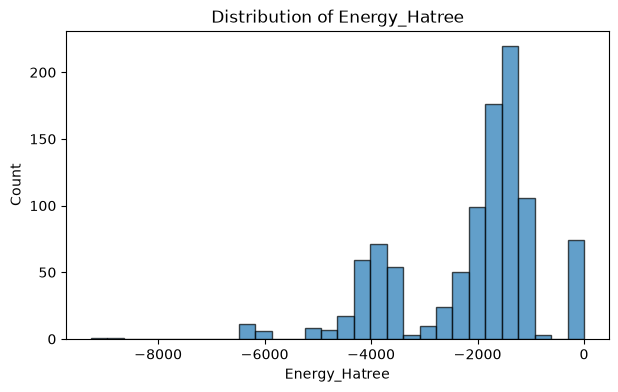

/var/folders/fv/9zptgcbd3591y8n1d18yqnlw0000gn/T/ipykernel_68042/257946871.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x=numeric_data["Energy_Hatree"], vert=False, patch_artist=True)


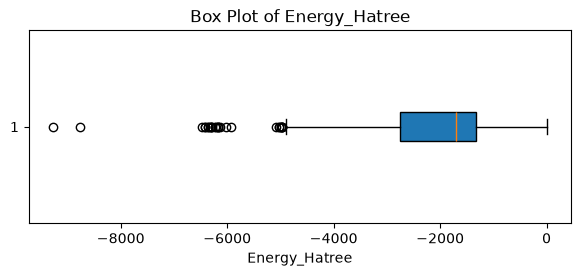

In [75]:
numeric_data = no_id_data.select_dtypes(include="number")
plt.figure(figsize=(7, 4))
plt.hist(numeric_data["Energy_Hatree"], bins=30, edgecolor='black', alpha=0.7)
plt.title("Distribution of Energy_Hatree")
plt.xlabel("Energy_Hatree")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
plt.boxplot(x=numeric_data["Energy_Hatree"], vert=False, patch_artist=True)
plt.title("Box Plot of Energy_Hatree")
plt.xlabel("Energy_Hatree")
plt.show()

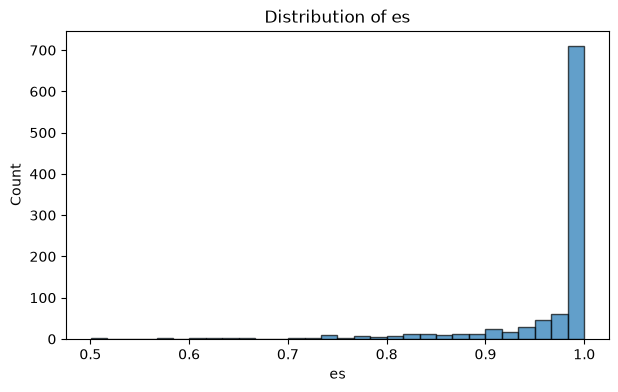

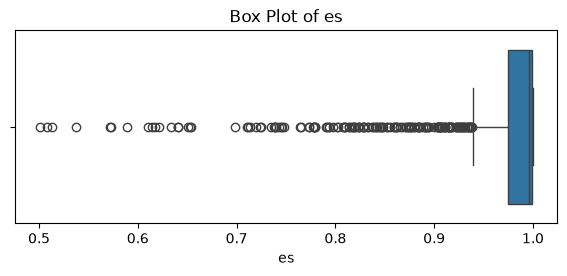

In [79]:
plt.figure(figsize=(7, 4))
plt.hist(numeric_data["es"], bins=30, edgecolor='black', alpha=0.7)
plt.title("Distribution of es")
plt.xlabel("es")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=numeric_data["es"])
plt.title("Box Plot of es")
plt.xlabel("es")
plt.show()

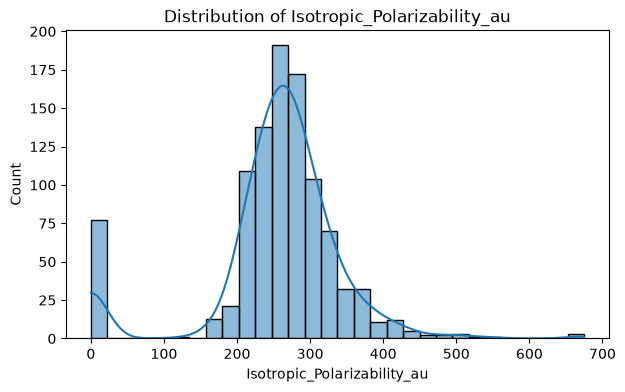

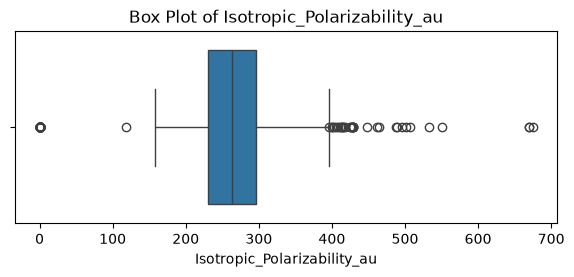

In [18]:
plt.figure(figsize=(7, 4))
sns.histplot(numeric_data["Isotropic_Polarizability_au"], bins=30, kde=True)
plt.title("Distribution of Isotropic_Polarizability_au")
plt.xlabel("Isotropic_Polarizability_au")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=numeric_data["Isotropic_Polarizability_au"])
plt.title("Box Plot of Isotropic_Polarizability_au")
plt.xlabel("Isotropic_Polarizability_au")
plt.show()

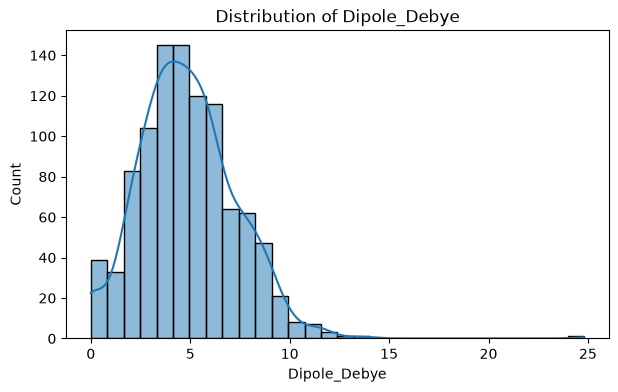

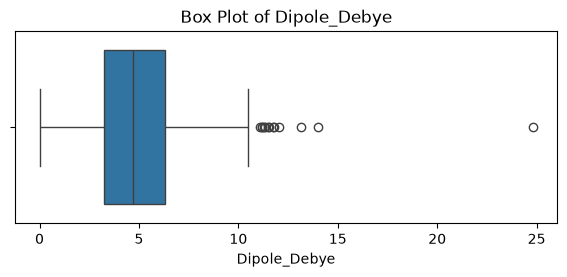

In [19]:
plt.figure(figsize=(7, 4))
sns.histplot(numeric_data["Dipole_Debye"], bins=30, kde=True)
plt.title("Distribution of Dipole_Debye")
plt.xlabel("Dipole_Debye")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=numeric_data["Dipole_Debye"])
plt.title("Box Plot of Dipole_Debye")
plt.xlabel("Dipole_Debye")
plt.show()

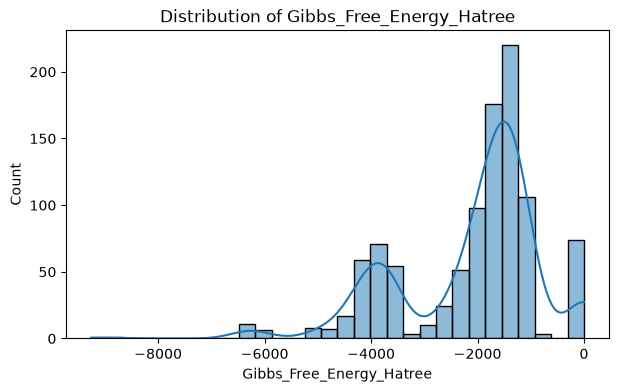

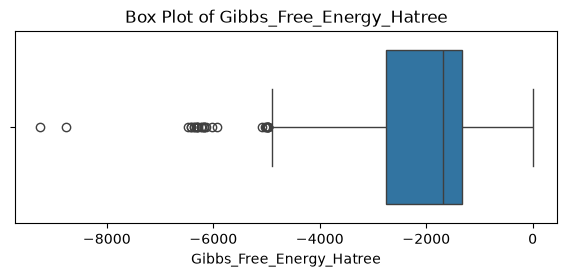

In [20]:
plt.figure(figsize=(7, 4))
sns.histplot(numeric_data["Gibbs_Free_Energy_Hatree"], bins=30, kde=True)
plt.title("Distribution of Gibbs_Free_Energy_Hatree")
plt.xlabel("Gibbs_Free_Energy_Hatree")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=numeric_data["Gibbs_Free_Energy_Hatree"])
plt.title("Box Plot of Gibbs_Free_Energy_Hatree")
plt.xlabel("Gibbs_Free_Energy_Hatree")
plt.show()

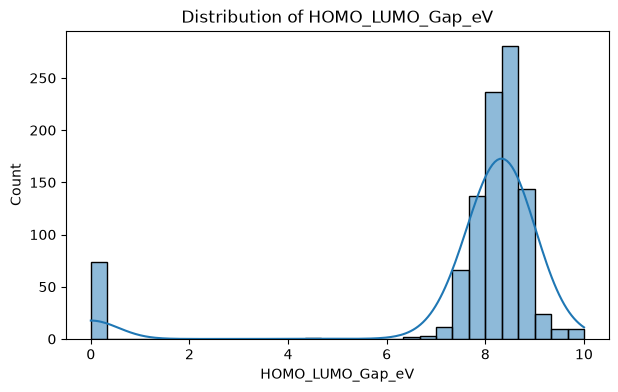

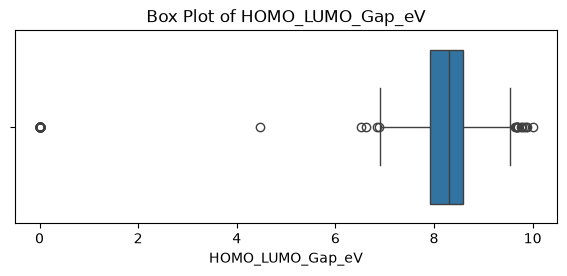

In [21]:
plt.figure(figsize=(7, 4))
sns.histplot(numeric_data["HOMO_LUMO_Gap_eV"], bins=30, kde=True)
plt.title("Distribution of HOMO_LUMO_Gap_eV")
plt.xlabel("HOMO_LUMO_Gap_eV")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=numeric_data["HOMO_LUMO_Gap_eV"])
plt.title("Box Plot of HOMO_LUMO_Gap_eV")
plt.xlabel("HOMO_LUMO_Gap_eV")
plt.show()

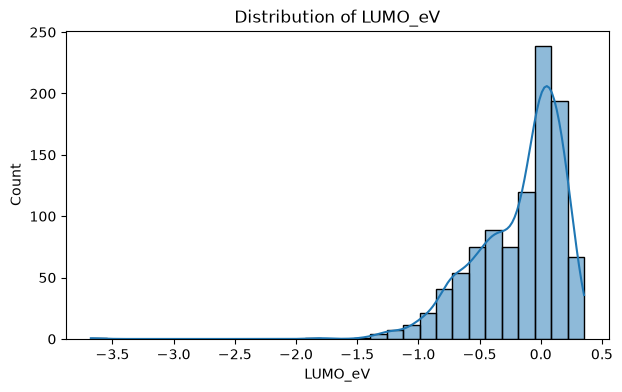

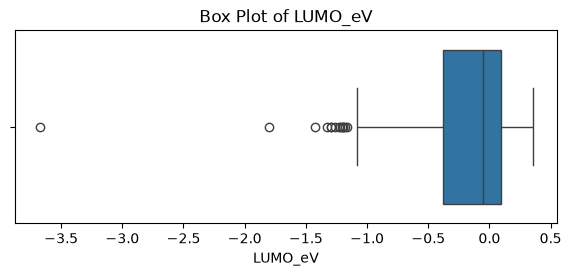

In [22]:
plt.figure(figsize=(7, 4))
sns.histplot(numeric_data["LUMO_eV"], bins=30, kde=True)
plt.title("Distribution of LUMO_eV")
plt.xlabel("LUMO_eV")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
sns.boxplot(x=numeric_data["LUMO_eV"])
plt.title("Box Plot of LUMO_eV")
plt.xlabel("LUMO_eV")
plt.show()

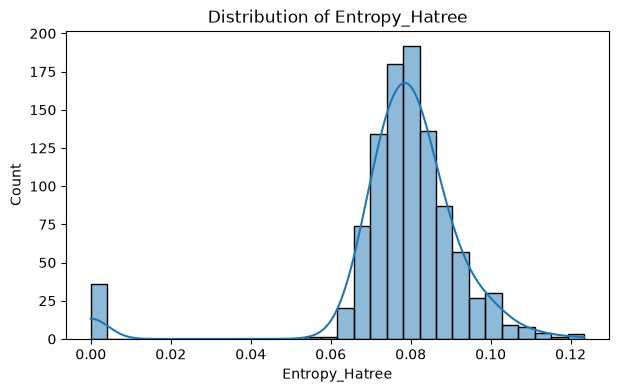

/var/folders/fv/9zptgcbd3591y8n1d18yqnlw0000gn/T/ipykernel_68042/1281469288.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(numeric_data["Entropy_Hatree"], vert=False)


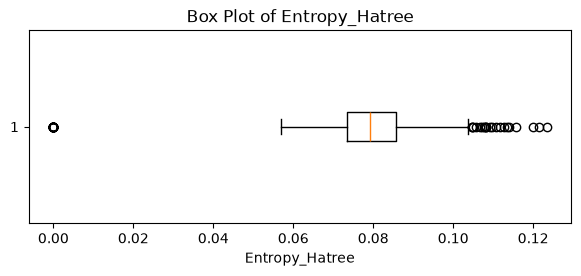

In [60]:
plt.figure(figsize=(7, 4))
sns.histplot(numeric_data["Entropy_Hatree"], bins=30, kde=True)
plt.title("Distribution of Entropy_Hatree")
plt.xlabel("Entropy_Hatree")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(7, 2.5))
plt.boxplot(numeric_data["Entropy_Hatree"], vert=False)
plt.title("Box Plot of Entropy_Hatree")
plt.xlabel("Entropy_Hatree")
plt.show()

### Distribution Findings

For at least three properties, record an observation, one plausible interpretation, and a limitation below. Cite the relevant statistic, row, or plot.

observation 1: The ES values are strongly left-skewed. Most polymers (approximately 70%) have ES values close to 1.0 with relatively little variation, while a smaller number of polymers exhibit much lower ES values over a wide range.

interpretation: Most polymers have similar ES characteristic with a small subset of polymers having a smaller more diverse values of ES, suggesting a degree of diversity in this dataset. 

limitation: The histogram and box plot alone cannot determine which molecular features are responsible for the lower ES 
values or whether these outliers arise from genuine chemical differences or computational uncertainty.


observation 2: In this group of polymers, the graphs for the properties: HOMO-LUMO gap and isotropic polarizability, have the same distribution of values.

interpretation: Both of these properties could have same underlying molecular properties

limitation: Unable to establish a direct relationship/correlation between the 2 properties


observation 3: Difference between the mean and medium for energy_hatree is relatively large with several local maximums within the distribution. 

interpretation: The difference between the mean and median suggests that the distribution is skewed, so the mean is influenced by a subset of polymers with more extreme energy values. Additionally, the presence of several local maxima may indicate that the dataset contains multiple groups of polymers with similar Energy_Hartree values.

limitation: The histogram alone cannot confirm whether the local maxima represent distinct polymer families or are simply due to the sampling distribution of the dataset.

## 3. Examine Relationships

Use the blank cells below to:

- produce labeled Pearson and Spearman correlation heatmaps for the 13 numeric properties;
- identify at least two strong relationships and inspect each with an appropriate scatter plot;
- find at least one pair for which Pearson and Spearman differ meaningfully;
- explain what the difference suggests and what it does not prove; and
- check whether any properties are exact or near-exact mathematical combinations of others.

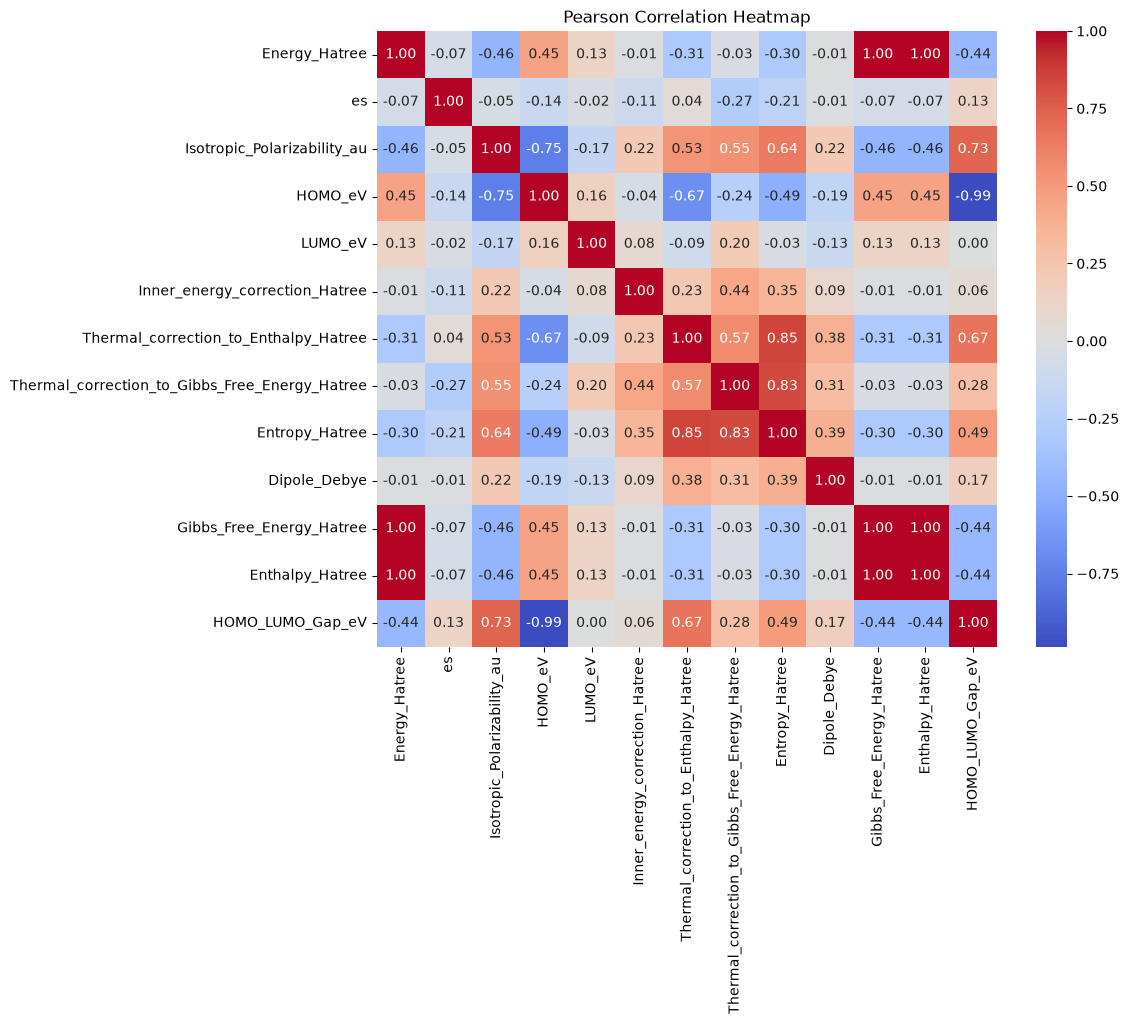

In [ ]:
pearson_corr = numeric_data.corr(method="pearson")

plt.figure(figsize=(10, 8))
pearson_corr = numeric_data.corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Pearson Correlation Heatmap")
plt.show()

plt.title("Pearson Correlation Heatmap")
plt.show()

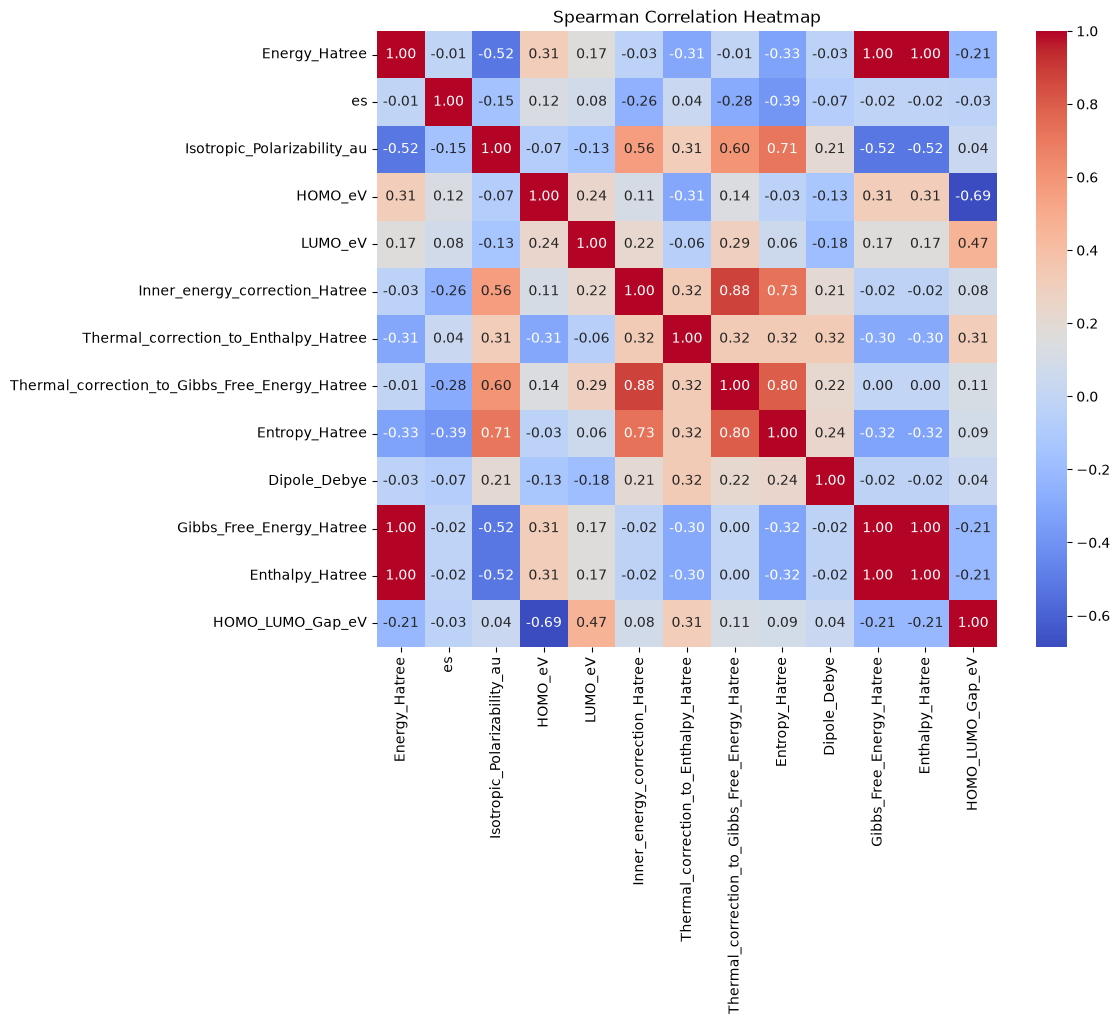

In [25]:
spearman_corr = numeric_data.corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Spearman Correlation Heatmap")
plt.show()

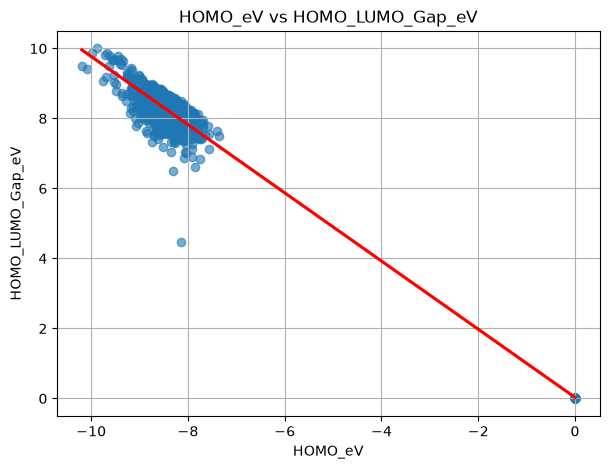

In [38]:
plt.figure(figsize=(7, 5))

sns.regplot(
    data=numeric_data,
    x="HOMO_eV",
    y="HOMO_LUMO_Gap_eV",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("HOMO_eV vs HOMO_LUMO_Gap_eV")
plt.xlabel("HOMO_eV")
plt.ylabel("HOMO_LUMO_Gap_eV")

plt.grid(True)
plt.show()

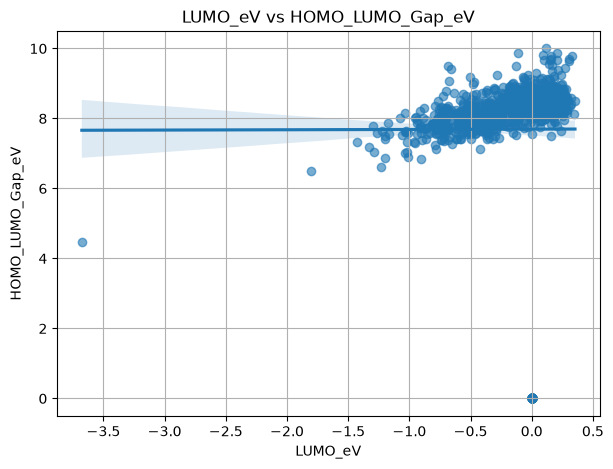

In [39]:
plt.figure(figsize=(7, 5))

sns.regplot(
    data=numeric_data,
    x="LUMO_eV",
    y="HOMO_LUMO_Gap_eV",
    scatter_kws={"alpha": 0.6}
)

plt.title("LUMO_eV vs HOMO_LUMO_Gap_eV")
plt.xlabel("LUMO_eV")
plt.ylabel("HOMO_LUMO_Gap_eV")

plt.grid(True)
plt.show()

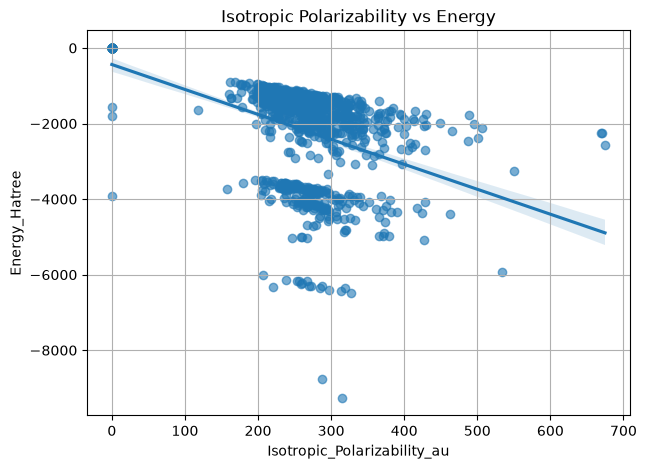

In [43]:
plt.figure(figsize=(7, 5))

sns.regplot(
    data=numeric_data,
    x="Isotropic_Polarizability_au",
    y="Energy_Hatree",
    scatter_kws={"alpha": 0.6}
)

plt.title("Isotropic Polarizability vs Energy")
plt.xlabel("Isotropic_Polarizability_au")
plt.ylabel("Energy_Hatree")

plt.grid(True)
plt.show()

### Relationship Findings

Explain the strongest relationships, the Pearson–Spearman contrast, and any mathematical dependencies below. Distinguish association from causation.

The plot between HOMO and the HOMO-LUMO gap has a very strong negative linear relationship with the spearman of -0.99. However, the peasron is less strong, being -0.69 pointing at a weakly monontonic relationship. This difference could be due to outliers, clusterings, both which are clearly represented on the scatter plot. Gap = LUMO - HOMO

If we also notice the pearson correlation between LUMO and the HOMO-LUMO gap, we can see the there is no correlation 0, between the 2 properties and can therefore speculate that for this data set, using their mathematical relationship, the variation in the HOMO-LUMO gap is almostly due to variation in the HOMO.

Another relationship worthy of highlight is the relationship between isotropic polarizability and energy. Again high peasron correlation but very low spearman correlation. The reason can be clearly seen in the scatter graph. There is strong linear relationship between the 2 properties, however clustering results in a very low spearman correlation. Outliers would also contribute, but clustering seems to be the main contributor. The clustering may be supported and explain by the distribution plot of the 2 properties suggesting 2 main groups of polymers with similar energy and polarizability.


Association is when there is a relationship observe between two things or in this case two properties. The presence of association does not necessarily give us the causation behind this association. The linear correlation suggests association but does not indicate causation. 

## 4. Standardize and Run PCA

Use the blank cells below to:

- standardize the 13 numeric properties with `StandardScaler`;
- verify numerically that standardization worked;
- run PCA on the standardized values;
- create a scree or individual explained-variance plot;
- create a cumulative explained-variance plot;
- create a PC1-versus-PC2 scores plot; and
- create a loading table or loading plot for PC1 and PC2.

Then state how many components you would retain and justify the choice using both explained variance and the purpose of the analysis. Interpret the strongest PC1 and PC2 loadings, inspect unusual score-plot points, and state at least two limitations of the projection.

### PCA Tool Map

Work through these checkpoints in order:

1. **Build `X`:** select the 13 numeric analytical properties and exclude `id`. Expected shape: `(number of rows, 13)`.
2. **Keep the names:** save the 13 column names before converting or scaling; scikit-learn commonly returns NumPy arrays without those labels.
3. **Standardize:** create `StandardScaler`, then use `fit_transform(X)`. The scaled array should have the same shape as `X`.
4. **Verify scaling:** calculate column means and population standard deviations on the scaled array. They should be approximately 0 and 1. Small floating-point values such as `1e-16` count as approximately zero.
5. **Fit PCA:** start with `PCA()` without choosing a reduced component count so you can inspect all components. Use `fit_transform()` on the standardized array to obtain row scores.
6. **Inspect variance:** use `explained_variance_ratio_` for individual proportions and `np.cumsum()` for cumulative proportions. The proportions should sum to approximately 1.
7. **Inspect component weights:** `components_` has one row per principal component and one column per original property. Transpose it and construct a labeled DataFrame using the saved property names.
8. **Plot scores:** columns 0 and 1 of the transformed score array are PC1 and PC2 coordinates for each polymer row.
9. **Choose retention:** state a rule, such as a cumulative-variance threshold or a visualization goal, and explain the information lost by that choice.

Common mistakes to avoid:

- including `id` because it is numeric;
- running PCA on properties with different scales without standardizing;
- calling `.fit_transform()` separately on different subsets;
- losing the property names when constructing the component table;
- confusing PCA **scores** (row coordinates) with component **weights** (how original properties form each component);
- assuming a large component weight proves causation or predictive importance; and
- worrying if every sign in a component is reversed—PCA directions have arbitrary sign.

`StandardScaler` uses population variance (`ddof=0`). A pandas `.std()` call uses sample standard deviation by default, so use a consistent definition when verifying unit variance. `PCA` centers inputs internally but does not put differently scaled properties onto comparable units; that is why the separate standardization step is still required.

In [26]:
columns_names = numeric_data.columns
columns_names

Index(['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'HOMO_eV',
       'LUMO_eV', 'Inner_energy_correction_Hatree',
       'Thermal_correction_to_Enthalpy_Hatree',
       'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree',
       'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree',
       'HOMO_LUMO_Gap_eV'],
      dtype='str')

In [27]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_data)
scaled_data.shape


(1000, 13)

In [28]:
scaled_data.mean(axis=0)
scaled_data.std(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [42]:
pca = PCA()
principal_components = pca.fit_transform(scaled_data)
pca.explained_variance_ratio_

array([4.04119053e-01, 1.94048588e-01, 1.06704410e-01, 8.36062372e-02,
       6.70321658e-02, 6.19984679e-02, 4.09680658e-02, 3.23721767e-02,
       6.56115484e-03, 2.58968063e-03, 2.98499559e-17, 0.00000000e+00,
       0.00000000e+00])

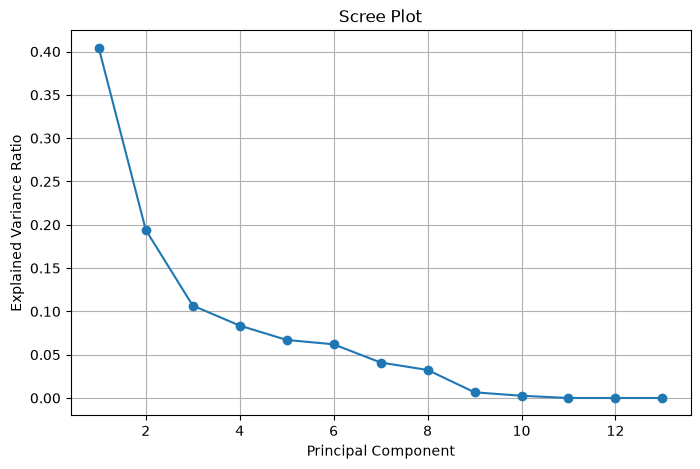

In [30]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.grid(True)

plt.show()

In [31]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
cumulative_variance

array([0.40411905, 0.59816764, 0.70487205, 0.78847829, 0.85551045,
       0.91750892, 0.95847699, 0.99084916, 0.99741032, 1.        ,
       1.        , 1.        , 1.        ])

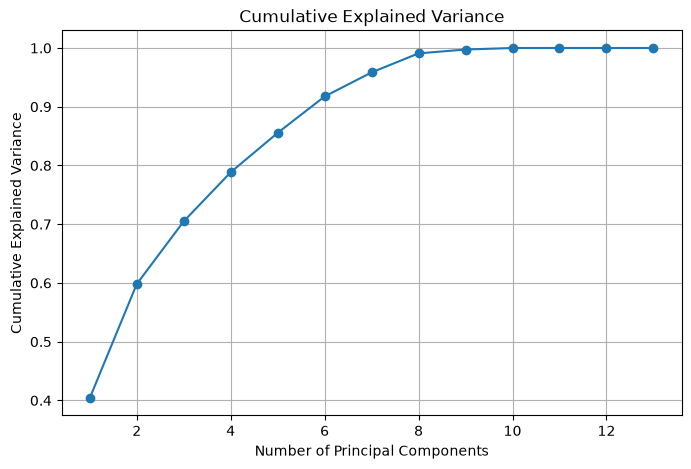

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.grid(True)

plt.show()

In [33]:
components = pca.components_
components

array([[-3.13684088e-01,  4.15299424e-03,  3.63260752e-01,
        -3.62002219e-01, -5.69311867e-02,  1.02131798e-01,
         3.43342337e-01,  2.25815357e-01,  3.37332479e-01,
         1.33123275e-01, -3.13668695e-01, -3.13658482e-01,
         3.57418193e-01],
       [ 3.86907784e-01, -1.96239425e-01,  8.44913126e-02,
         1.84351026e-02,  1.23975980e-01,  2.76011730e-01,
         2.25546627e-01,  4.46763455e-01,  3.21503864e-01,
         2.43820473e-01,  3.86940155e-01,  3.86980970e-01,
         1.52409349e-03],
       [ 2.55745958e-01,  4.79930351e-01,  6.85291745e-02,
        -3.78714350e-01, -2.40387454e-01, -3.45774735e-01,
         1.55551883e-01, -2.44628464e-01, -1.33636095e-01,
         1.65790181e-01,  2.55729123e-01,  2.55656778e-01,
         3.44458305e-01],
       [ 3.75204337e-02,  2.59771280e-01,  1.20983722e-02,
        -1.40331688e-01,  7.80055769e-01,  7.73051753e-02,
        -2.15728636e-02,  7.92793500e-02, -9.09451323e-02,
        -4.54402065e-01,  3.75261188e

In [34]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(columns_names))],
    index=columns_names
)


loadings["PC1"].sort_values(key=abs, ascending=False)

Isotropic_Polarizability_au                       0.363261
HOMO_eV                                          -0.362002
HOMO_LUMO_Gap_eV                                  0.357418
Thermal_correction_to_Enthalpy_Hatree             0.343342
Entropy_Hatree                                    0.337332
Energy_Hatree                                    -0.313684
Gibbs_Free_Energy_Hatree                         -0.313669
Enthalpy_Hatree                                  -0.313658
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.225815
Dipole_Debye                                      0.133123
Inner_energy_correction_Hatree                    0.102132
LUMO_eV                                          -0.056931
es                                                0.004153
Name: PC1, dtype: float64

In [49]:
loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
Energy_Hatree,-0.313684,0.386908,0.255746,0.037520,-0.102595,0.068109,0.000242,0.006025,-0.051628,0.023597,-4.883402e-01,-5.422708e-01,3.662431e-01
es,0.004153,-0.196239,0.479930,0.259771,0.684466,0.190645,-0.268309,0.283230,0.028274,0.076236,-1.556583e-16,5.878204e-16,1.714645e-16
Isotropic_Polarizability_au,0.363261,0.084491,0.068529,0.012098,-0.230763,0.180228,0.166819,0.630849,-0.549389,-0.206639,1.916302e-15,-2.841125e-15,3.817339e-15
HOMO_eV,-0.362002,0.018435,-0.378714,-0.140332,0.232504,-0.083909,-0.203512,0.149742,-0.254348,-0.126400,1.064707e-01,3.228244e-01,6.199493e-01
LUMO_eV,-0.056931,0.123976,-0.240387,0.780056,0.132456,-0.448404,0.200218,-0.029149,-0.206486,-0.000823,-1.712423e-02,-5.192151e-02,-9.970965e-02
Inner_energy_correction_Hatree,0.102132,0.276012,-0.345775,0.077305,0.348162,0.680413,0.384119,-0.235228,-0.016523,0.022793,8.136183e-05,-1.796151e-04,7.955731e-05
Thermal_correction_to_Enthalpy_Hatree,0.343342,0.225547,0.155552,-0.021573,0.117204,-0.072087,-0.378257,-0.508468,-0.282896,-0.553174,4.106716e-08,-9.066025e-08,4.015633e-08
Thermal_correction_to_Gibbs_Free_Energy_Hatree,0.225815,0.446763,-0.244628,0.079279,0.023509,-0.057624,-0.252908,0.394592,0.630548,-0.249304,-5.670227e-05,1.044135e-05,4.301008e-06
Entropy_Hatree,0.337332,0.321504,-0.133636,-0.090945,0.039006,-0.089666,-0.378014,-0.040579,-0.231991,0.740803,-8.427433e-16,5.031159e-15,2.867823e-15
Dipole_Debye,0.133123,0.243820,0.165790,-0.454402,0.438517,-0.479025,0.513989,0.052320,0.012617,-0.004290,-3.507956e-17,-2.051875e-16,-2.834207e-16


In [35]:
loadings["PC2"].sort_values(key=abs, ascending=False)

Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.446763
Enthalpy_Hatree                                   0.386981
Gibbs_Free_Energy_Hatree                          0.386940
Energy_Hatree                                     0.386908
Entropy_Hatree                                    0.321504
Inner_energy_correction_Hatree                    0.276012
Dipole_Debye                                      0.243820
Thermal_correction_to_Enthalpy_Hatree             0.225547
es                                               -0.196239
LUMO_eV                                           0.123976
Isotropic_Polarizability_au                       0.084491
HOMO_eV                                           0.018435
HOMO_LUMO_Gap_eV                                  0.001524
Name: PC2, dtype: float64

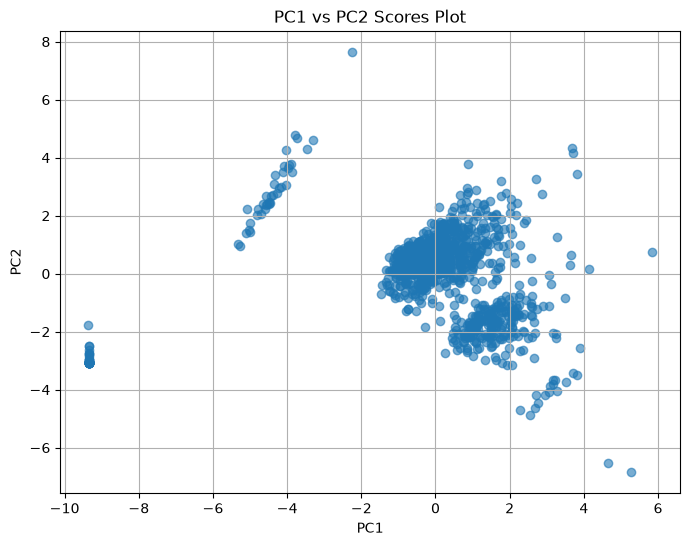

In [36]:
plt.figure(figsize=(8, 6))

plt.scatter(
    principal_components[:, 0],
    principal_components[:, 1],
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PC1 vs PC2 Scores Plot")

plt.grid(True)
plt.show()

In [37]:
loadings[["PC1", "PC2"]]

,PC1,PC2
Energy_Hatree,-0.313684,0.386908
es,0.004153,-0.196239
Isotropic_Polarizability_au,0.363261,0.084491
HOMO_eV,-0.362002,0.018435
LUMO_eV,-0.056931,0.123976
Inner_energy_correction_Hatree,0.102132,0.276012
Thermal_correction_to_Enthalpy_Hatree,0.343342,0.225547
Thermal_correction_to_Gibbs_Free_Energy_Hatree,0.225815,0.446763
Entropy_Hatree,0.337332,0.321504
Dipole_Debye,0.133123,0.243820


### PCA Findings

Record your component-retention decision, loading interpretation, unusual observations, and at least two limitations below.

PC1 + PC2 = 59.8%
PC1–PC5 = 85.6%
PC1–PC6 = 91.8%

I chose to retain the first five principal components because they explain approximately 85.6% of the total variance in the dataset. This provides a substantial reduction from the original 13 properties while preserving most of the information. The remaining 14.4% variance is discarded, meaning that smaller patterns or subtle variations captured by higher principal components may be lost.


PC1 showed the main property trends were Isotropic Polarizability, HOMO, HOMO-LUMO gap, Thermal correction to Enthalpy, Energy and Enthalpy.


Observation: There is a small group consisting of a few polymers on the right that show to be quite different from majority of the polymers. 

Interpretation: This could be due to polymers being different size and energies. This could also be the results the 0s within the data set. The origin of the 0 is unknown.


Limitations:
PCA components are mathematical combinations of many variables rather than direct physical properties. Therefore, while loadings indicate which variables contribute most, the meaning of each principal component is not always chemically straightforward.

In the process of reducing information, some chemically revelant information might be lost.





## 5. Critical-Thinking Questions

Answer every question below. Each answer must cite a specific number, table, row, or plot from this notebook.

### 5.1 Dataset structure

Which columns are identifiers, structures, categories, or numeric analytical variables, and why does that distinction matter?

In [41]:
no_id_data = data.drop(columns="id")
dictionary = pd.DataFrame({
    "Column Name": no_id_data.columns, 
    "Classification": [
        "Identifier",
        "Chemical structure",
        "Chemical structure",
        "Chemical structure",
        "Chemical structure",
        "Categorical metadata",
        *["Numeric analytical variable"] * 13,
        "Categorical metadata",
        "Categorical metadata",
        "Categorical metadata"
    ]
})
dictionary 

,Column Name,Classification
0,Name,Identifier
1,reactant_1,Chemical structure
2,reactant_2,Chemical structure
3,psmiles,Chemical structure
4,SMILES,Chemical structure
5,reaction_type,Categorical metadata
6,Energy_Hatree,Numeric analytical variable
7,es,Numeric analytical variable
8,Isotropic_Polarizability_au,Numeric analytical variable
9,HOMO_eV,Numeric analytical variable


This is important as it makes it easier to identify the columns that contain the data which require analysing. (dictionary)

### 5.2 Descriptive statistics

When do the mean and median describe different “typical” values, and what does that reveal about distribution shape?

When the mean and median have different values: if the difference is big, it means that the distribution is skewed, containing many extremes value on one side of the distribution, influencing the mean significantly, but not as much to the median. (the distribution of Energy_Hatree)

### 5.3 Data quality

Does “zero missing values” prove that the dataset is complete? Which zero or extreme values deserve investigation?

No, zero missing values does not prove thta the dataset is complete. NaN or N/A could be represented by 0s.

In this data set, I believe all the 0s deserves to be investigated. Energy and all the associated properties are unlikely to be 0s. 

Also the extreme values in polarizability around 700 au, there is 0 values between 550 and 700 and also they deviate a lots from the line of best fit from the energy vs polarizability plot. (openpoly_calculated_properties_csv)

### 5.4 Histograms and density plots

Is a variable symmetric, skewed, multimodal, bounded, or concentrated at a special value? What evidence supports the description?

concentrated = ES -- 1 massive peak

multimodal = energy and gibbs free energy -- multiple peaks 

skewed = polarizabillity and homo-lumo gap -- mean and median differ by a lot and a long tail

(distribution plots of ES, Energy_Hatree, Gibbs free energy, polarizability, homo-lumo gap)

### 5.5 Box plots and outliers

What do the median, box, whiskers, and points beyond the whiskers reveal? Why is a box-plot outlier not automatically an error?

median reveals the middle value

box reveals the middle 50% of the values 

whiskers reveals the spread of the overall data

points beyond are listed as outliers and they do not automatically considered as an error as there is potential that they are just usual results. 

(box plots)


### 5.6 Scale

How do units and numerical ranges affect comparisons among variables?

Variables which have different units and numerical ranges cannot be compared. 

### 5.7 Correlation

What relationship does Pearson detect, what relationship does Spearman detect, and why can their values differ?

Pearson detects a linear relationship.

Spearman detects Monotonic relationship.

Their value can differ as the ranking of the value could always increase and have a non-linear relationship vice versa, a linear relationship could have outliers and variation that lowers its monotonic relationship.

(pearson correlation plot and spearman correlation plot)

### 5.8 Standardization

What changes after z-score standardization, what stays the same, and why should it happen before PCA here?

The mean and standard deviation would change. The correlations and trend stay the same. Having z-score standardization allows all the units to be removed and values standardisation to make the values more comparable. (CHAT-GPT)

### 5.9 PCA

How many components retain a useful amount of variance? Which original properties shape PC1 and PC2?

The goal is to retain maximum information while using the least amount of components. 

PC1 is shaped mainly by Isotropic Polarizability, HOMO, HOMO-LUMO gap, Thermal correction to Enthalpy, Energy and Enthalpy. 

PC2 is shaped mainly by Thermal_correction_to_Gibbs_Free_Energy_Hatree, Energy, Gibbs Free eneryg and Enthalpy.

(loadings)

### 5.10 PCA limitations

Does high explained variance imply prediction, causation, or scientific importance? What information can a two-dimensional projection hide?

High explained variance does not imply any of the above. It depends on the variable under consideration for prediction, causation or scientific importance and as principle components contain multiple, it can not provide the information required but only the direction of the greatest variance. (PC1 vs PC2 plot)

## 6. Review Your Work

Ask Codex to review this notebook for calculation errors, unsupported interpretations, and reproducibility. Record below:

- one suggestion you accepted;
- one suggestion you changed or rejected; and
- the evidence you used to make each decision.

You remain responsible for the final analysis.

## Codex Review

### Accepted suggestion
I corrected the interpretation of the HOMO versus HOMO–LUMO gap relationship. The original description incorrectly reported the Spearman correlation sign and mixed Pearson and Spearman interpretations. I accepted this suggestion because the correlation matrix showed a value of approximately −0.99, and the scatter plot showed a strong decreasing trend. Pearson and Spearman were then described separately as measures of linear and monotonic association.

### Changed/rejected suggestion
The review suggested treating zero values as possible missing-coded values. I did not remove or replace these observations because there was insufficient evidence that zeros represented missing data. Instead, I treated them as suspicious values requiring investigation. The evidence used was the absence of missing values from pandas checks and the lack of documentation indicating that zero values represent missing observations.

### Evidence used
The decision was based on:
- summary statistics,
- correlation results,
- PCA outputs,
- and inspection of the original data values.

## Bonus: Connect SVD to PCA

Starting with the standardized data matrix:

1. Write its SVD as $X = U\Sigma V^\top$.
2. Explain which matrix contains the principal directions.
3. Show how the singular values determine explained variance.
4. Compare the result with scikit-learn's PCA output.

In [48]:
U, S, VT = np.linalg.svd(scaled_data, full_matrices=False)

svd_variance_ratio = S**2 / np.sum(S**2)

print(svd_variance_ratio
)
VT[:2]
pca.components_[:2]

[4.04119053e-01 1.94048588e-01 1.06704410e-01 8.36062372e-02
 6.70321658e-02 6.19984679e-02 4.09680658e-02 3.23721767e-02
 6.56115484e-03 2.58968063e-03 9.77490902e-33 1.44487251e-33
 9.38611691e-34]


array([[-0.31368409,  0.00415299,  0.36326075, -0.36200222, -0.05693119,
         0.1021318 ,  0.34334234,  0.22581536,  0.33733248,  0.13312327,
        -0.31366869, -0.31365848,  0.35741819],
       [ 0.38690778, -0.19623943,  0.08449131,  0.0184351 ,  0.12397598,
         0.27601173,  0.22554663,  0.44676345,  0.32150386,  0.24382047,
         0.38694016,  0.38698097,  0.00152409]])

The standardized data matrix X can be decomposed using singular value decomposition (SVD):

\[
X = U\Sigma V^T
\]

where U contains the polymer scores, Σ contains the singular values representing the magnitude of variation, and Vᵀ contains the principal directions (loadings).

The principal directions are contained in Vᵀ from the SVD decomposition. Each row of Vᵀ represents a principal component direction and contains the weights (loadings) of the original variables. These weights describe how each original property contributes to each principal component.

The singular values in Σ determine the explained variance of each principal component. The variance contribution of each component is proportional to the square of its singular value:

\[
\text{Explained variance ratio}_i =
\frac{\sigma_i^2}{\sum_j\sigma_j^2}
\]

Therefore, larger singular values correspond to principal components that capture more variation in the standardized dataset. The explained variance ratios obtained from SVD should match the values reported by scikit-learn PCA.

## Deliverables

Submit one pull-request link containing:

1. `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`; and
2. a pull-request description naming:
   - the dataset;
   - your main data-quality concern;
   - the number of PCA components you retained and why;
   - one Codex suggestion you accepted and one you changed or rejected; and
   - links to any GitHub Issues you opened, or “None.”

Keep the critical-question answers in this notebook as Markdown so the code, evidence, and reasoning stay together.

## Submission Checklist

- [ ] My work is on a branch named `s02/<github-username>`.
- [ ] This completed notebook is saved as `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`.
- [ ] The notebook loads the supplied CSV through a relative path and does not modify it.
- [ ] Restarting the kernel and running all cells completes without errors.
- [ ] The audit covers shape, roles, dtypes, missing values, uniqueness, duplicates, constants, zeros, and suspicious values.
- [ ] The descriptive-statistics table includes all 13 numeric properties.
- [ ] At least six properties have readable distribution and box-plot analysis.
- [ ] At least three unusual observations are inspected rather than automatically deleted.
- [ ] Both labeled Pearson and Spearman correlation analyses are present.
- [ ] At least two strong relationships and one Pearson–Spearman difference are interpreted.
- [ ] PCA uses the 13 standardized properties and excludes `id`.
- [ ] Explained variance, cumulative variance, PC1–PC2 scores, and PC1/PC2 loadings are shown and interpreted.
- [ ] Every critical question has an evidence-based answer.
- [ ] Observation, interpretation, and limitation are clearly distinguished.
- [ ] The AI-review reflection shows that I evaluated rather than automatically accepted advice.
- [ ] My pull-request description names the dataset, my main data-quality concern, my PCA retention decision, my AI-review decisions, and links to any Issues—or “None.”
- [ ] The pull request is ready for review.